# DBA5106 Project 1: portfolio optimization as a linear regression

## Introduction

We compare two portfolios of the 98 assets on the 2nd validation set (2026-01-02 to 2026-07-31). The equally
weighted portfolio (EW) reaches a daily Sharpe ratio of 0.111, while the minimum-variance portfolio (MinVar),
estimated from the previous 126 days, reaches only 0.021. Written as a linear regression, MinVar has 97 features and
only 126 observations, which suggests that it overfits its training window.

In this notebook we:

1. rebuild EW and MinVar, with MinVar written as a linear regression;
2. build LASSO and Ridge portfolios, with λ chosen by cross-validation, to reduce the overfitting;
3. try five explorations with the data + loss + structure + constraint framework;
4. choose one final procedure for the August test month, with a rule fixed in advance.

We use two periods before the test month: the 2nd validation set (145 trading days) and, as an extra check with the
same code, 2025-01-02 to 2025-12-31 (250 trading days).

**Layout.** Part 1 (sections 1 to 6) builds every portfolio for every validation day and saves the daily returns in
`results/`. Part 2 (sections 7 to 10) reads the saved results and makes the tables and figures. The conclusion is at
the end.

## Part 1. Experiments

### 1. Settings

In [1]:
import warnings
from pathlib import Path

import cvxpy as cp
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LassoCV, LinearRegression, Ridge, RidgeCV
from sklearn.model_selection import KFold, validation_curve

- `DATA_FILE`: the data file, looked for in the folder of this notebook and then in a `data` folder one level up.
  `RESULTS`: the folder where the daily results, tables and figures are saved.
- `WINDOW`: the 126 past days used to build each portfolio (about half a year of trading days).
- `LONG_WINDOW`: the 1008-day window of exploration 5.1.
- `ALPHAS`: the 101 values of λ we try, from $10^{-8}$ to $10^{8}$. scikit-learn calls λ `alpha`.
- `NO_SHORT_ALPHAS`: 21 values of λ over the same range, for exploration 5.5, whose fits are slower.
- `FOLDS`: the 5 folds used in every cross-validation. The days are shuffled with a fixed seed, so every run uses the
  same folds. Shuffling is fine here because daily returns show no clear time pattern.
- `MAX_ITER`: LASSO improves β in repeated rounds until β stops changing, and `MAX_ITER` caps the number of rounds.
  With a very small λ it sometimes reaches the cap first and warns "did not converge". Rerunning those days of 2026
  with 1,000,000 rounds changed no saved number by more than 0.000002.
- `PERIODS`: the first and last day of each period.

In [2]:
HERE = Path.cwd()
DATA_FILE = HERE / "100_Portfolios_10x10_Daily.csv"
if not DATA_FILE.exists():
    DATA_FILE = HERE.parent / "data" / "100_Portfolios_10x10_Daily.csv"
RESULTS = HERE / "results"

WINDOW = 126
LONG_WINDOW = 1008
ALPHAS = np.logspace(-8, 8, 101)
NO_SHORT_ALPHAS = np.logspace(-8, 8, 21)
FOLDS = KFold(n_splits=5, shuffle=True, random_state=0)
MAX_ITER = 100_000
PERIODS = {"2026": ("2026-01-02", "2026-07-31"), "2025": ("2025-01-02", "2025-12-31")}

### 2. Data

We use the second table (Average Equal Weighted Returns, Daily) of the 100 Portfolios Formed on Size and
Book-to-Market daily file (returns in percent). Our copy of the file keeps only this
table, so `load_returns()` skips its one title line (`skiprows=1`). Each column is one asset: a group of stocks, sorted by company size.

`load_returns()` reads the file, removes `ME9 BM10` and `BIG HiBM`, the two columns with missing data, which leaves
98 assets, and records the size group (1 to 10) of each asset. The file lists the assets 10 at a time, from the
smallest to the largest companies, so column `k` (counting from 0) is in size group
`k // 10 + 1` (`//` divides and rounds down). The size groups are set before the two
columns are removed. The last lines check that no missing value (−99.99 or −999) is left in the rows we use.

In [3]:
def load_returns():
    data = pd.read_csv(DATA_FILE, skiprows=1, index_col=0)
    data.index = pd.to_datetime(data.index.astype(str).str.strip(), format="%Y%m%d")
    data.columns = data.columns.str.strip()
    size_group = pd.Series([k // 10 + 1 for k in range(100)], index=data.columns)
    data = data.drop(columns=["ME9 BM10", "BIG HiBM"])
    return data, size_group[data.columns].values


returns, groups = load_returns()
print(returns.shape[0], "days and", returns.shape[1], "assets")
print("from", returns.index[0].date(), "to", returns.index[-1].date())

first_row = returns.index.get_loc(pd.Timestamp("2025-01-02"))
used_rows = returns.iloc[first_row - LONG_WINDOW:].loc[:"2026-07-31"]
assert (used_rows > -99.99).all().all(), "missing values in the rows we use"

26296 days and 98 assets
from 1926-07-01 to 2026-07-31


### 3. The minimum-variance portfolio as a linear regression

We write the weights of the $p = 98$ assets as

$$w = w_{\text{EW}} - N\beta, \qquad w_{\text{EW}} = \tfrac{1}{p}\mathbf{1}, \qquad
N = \begin{pmatrix} I_{p-1} \\ -\mathbf{1}^{\top} \end{pmatrix}.$$

Every column of $N$ adds up to 0, so the weights add up to 1 for any $\beta$, and $\beta = 0$ gives EW. With $R$ the
returns of the window (one row per day, one column per asset), MinVar comes from the OLS regression

$$\min_{\alpha,\,\beta}\ \lVert y - (\alpha + X\beta) \rVert_2^2, \qquad y = R\,w_{\text{EW}}, \qquad X = R\,N.$$

The portfolio's return on each day is $y - X\beta$, so the regression keeps it as close to a constant as possible,
which gives the lowest variance. On its own, $\beta$ has no intuitive meaning, so we always turn it into weights.

We compare the portfolios by the Sharpe ratio of their daily returns $r_1, \dots, r_n$:

$$\text{Sharpe} = \frac{\bar r}{s_r},$$

the average daily return divided by its standard deviation (`ddof=1` divides by $n - 1$).

In [4]:
def make_N(p):
    return np.vstack([np.eye(p - 1), -np.ones((1, p - 1))])


def regression_data(R):
    p = R.shape[1]
    w_ew = np.ones(p) / p
    return R @ w_ew, R @ make_N(p)


def to_weights(beta, p):
    return np.ones(p) / p - make_N(p) @ beta


def sharpe(r):
    return r.mean() / r.std(ddof=1)

### 4. Baseline: MinVar, LASSO and Ridge

LASSO and Ridge add a penalty to the same regression. In scikit-learn's scaling, which the code uses,

$$\text{LASSO:}\quad \min_{\alpha,\,\beta}\ \frac{1}{2n}\lVert y - (\alpha + X\beta) \rVert_2^2 + \lambda \lVert \beta \rVert_1$$

$$\text{Ridge:}\quad \min_{\alpha,\,\beta}\ \lVert y - (\alpha + X\beta) \rVert_2^2 + \lambda \lVert \beta \rVert_2^2$$

- `fit_minvar`: OLS with an intercept.
- `fit_lasso`: `LassoCV` tries every λ in `ALPHAS` on the 5 folds, keeps the one with the lowest average MSE on the
  held-out folds, and refits on the whole window. There is no standardization, because all returns are in percent.
- `fit_ridge`: the same with `RidgeCV`. `scoring="neg_mean_squared_error"` makes Ridge use the MSE as well (otherwise
  it would use R²). scikit-learn keeps the highest score, hence the minus sign.

Both also return the fitted model, so that the chosen λ can be saved; exploration 5.4 also reuses the fold errors
stored in the LASSO model.

In [5]:
def fit_minvar(R):
    y, X = regression_data(R)
    beta = LinearRegression().fit(X, y).coef_
    return to_weights(beta, R.shape[1])


def fit_lasso(R):
    y, X = regression_data(R)
    model = LassoCV(alphas=ALPHAS, cv=FOLDS, max_iter=MAX_ITER).fit(X, y)
    return to_weights(model.coef_, R.shape[1]), model


def fit_ridge(R):
    y, X = regression_data(R)
    model = RidgeCV(alphas=ALPHAS, cv=FOLDS, scoring="neg_mean_squared_error").fit(X, y)
    return to_weights(model.coef_, R.shape[1]), model

**Debug checks.** We first check the code against three known values: 2026-01-02 is row 26,152; with only the first 6 assets,
the MinVar weights for 2026-01-02 are −0.111, −0.199, 0.348, 0.46, 0.006 and 0.496; and that portfolio's return on
2026-01-02 is 1.393.

In [6]:
def debug_checks(returns):
    i = returns.index.get_loc(pd.Timestamp("2026-01-02"))
    assert i + 1 == 26152, "2026-01-02 should be row 26152"

    first6 = returns.values[i - WINDOW:i, :6]
    w = fit_minvar(first6)
    assert np.allclose(w.round(3), [-0.111, -0.199, 0.348, 0.46, 0.006, 0.496])
    assert round(returns.values[i, :6] @ w, 3) == 1.393
    print("Debug checks: all three match")


debug_checks(returns)

Debug checks: all three match


### 5. Explorations

We implemented improvements using the data + loss + structure + constraint framework. Each idea below is applied
to both LASSO and Ridge. The first four were planned, with their reasons, before we ran them; the fifth was added
later (see 5.5).

#### 5.1 Data: a longer window

97 coefficients from 126 days is little data. A common rule of thumb asks for about 10 observations per feature,
about 970 days here, so LASSO and Ridge are also built from the last 1008 days (about four years). This happens
inside `build_portfolios` (section 6), so there is no new function. Older days may behave differently from the days
the portfolio is used on. In an earlier run we also tried 252 and 504 days; they gave similar or slightly lower Sharpe ratios over
both periods together, so only the 1008-day window is kept. The final choice is the same with or without them.

#### 5.2 Loss: λ chosen by the Sharpe ratio

Cross-validation chooses λ by the MSE, which only measures how much the portfolio's returns move around their
average, while the portfolios are compared by the Sharpe ratio. For each λ and each fold, `fit_by_sharpe` fits on the
other four folds, turns β into weights and computes the Sharpe ratio of the portfolio's returns `R[val] @ w` on the
held-out fold. It keeps the λ with the highest average and refits on the whole window. The λ values are tried from
the largest to the smallest (`reversed`), and with `warm_start=True` each LASSO fit starts from the previous answer,
which only makes it faster.

In [7]:
def fit_by_sharpe(R, model):
    y, X = regression_data(R)
    p = R.shape[1]
    score = np.zeros(len(ALPHAS))

    for train, val in FOLDS.split(X):
        for k in reversed(range(len(ALPHAS))):
            model.set_params(alpha=ALPHAS[k]).fit(X[train], y[train])
            w = to_weights(model.coef_, p)
            score[k] += sharpe(R[val] @ w) / FOLDS.get_n_splits()

    best = ALPHAS[np.argmax(score)]
    model.set_params(alpha=best).fit(X, y)
    return to_weights(model.coef_, p), best

#### 5.3 Structure: one weight per size group

Assets of a similar size tend to move together, so many of the 97 separate coefficients may only fit noise.
`group_returns` averages the assets of each size group, which gives 10 returns. The same LASSO and Ridge are fitted
on these 10 columns (9 coefficients, 14 days per coefficient), and `spread_to_assets` shares each group's weight
equally among its assets. Here β = 0 gives each size group 1/10 of the money, which is close to EW but not the same,
because groups 9 and 10 have 9 assets each.

In [8]:
def group_returns(R, groups):
    return np.column_stack([R[:, groups == g].mean(axis=1) for g in range(1, 11)])


def spread_to_assets(v, groups):
    return np.array([v[g - 1] / np.sum(groups == g) for g in groups])

#### 5.4 Constraints: a larger λ with the one-standard-error rule

The λ with the lowest CV error, $\lambda^\star$, is itself estimated from five small folds, so it is noisy. The
one-standard-error rule takes the largest λ whose average CV error is within one standard error of the lowest:

$$\lambda_{\text{1SE}} = \max\left\{\lambda : \overline{\text{MSE}}(\lambda) \le \overline{\text{MSE}}(\lambda^\star) +
\text{SE}(\lambda^\star)\right\}, \qquad \text{SE}(\lambda^\star) = \frac{\text{SD of the 5 fold errors at }
\lambda^\star}{\sqrt{5}} .$$

A larger λ means a smaller region for β, which is why this idea
is listed under constraints, and it keeps the portfolio closer to EW. `fold_mse` has one row per λ and one column per fold. `LassoCV` already
stores it as `mse_path_`; for Ridge it is computed with `validation_curve`, which returns minus the MSE.

In [9]:
def one_se_alpha(alphas, fold_mse):
    mean = fold_mse.mean(axis=1)
    se = fold_mse.std(axis=1, ddof=1) / np.sqrt(fold_mse.shape[1])
    best = np.argmin(mean)
    return alphas[mean <= mean[best] + se[best]].max()


def fit_one_se(R, lasso_model):
    y, X = regression_data(R)
    p = R.shape[1]

    a_lasso = one_se_alpha(lasso_model.alphas_, lasso_model.mse_path_)
    w_lasso = to_weights(Lasso(alpha=a_lasso, max_iter=MAX_ITER).fit(X, y).coef_, p)

    _, scores = validation_curve(Ridge(), X, y, param_name="alpha", param_range=ALPHAS,
                                 cv=FOLDS, scoring="neg_mean_squared_error")
    a_ridge = one_se_alpha(ALPHAS, -scores)
    w_ridge = to_weights(Ridge(alpha=a_ridge).fit(X, y).coef_, p)
    return (w_lasso, a_lasso), (w_ridge, a_ridge)

#### 5.5 Constraints: no negative weights ("no-short")

MinVar uses large negative weights: its absolute weights add up to about 12 on average in 2026 (Table 1). This
exploration solves the same LASSO and Ridge problems as in section 4 with one extra rule,

$$w_{\text{EW}} - N\beta \ge 0 ,$$

so that no weight is negative. Like the penalty, the rule limits how far β can move, so it may also reduce
overfitting.

scikit-learn cannot add this rule, so the same objectives are solved with cvxpy, a Python package that solves
optimization problems written almost as they appear on paper (it uses the solver CLARABEL). The intercept is handled by
centering $y$ and $X$, which gives the same β. λ is chosen as in section 4: the lowest average MSE on the
same 5 folds, with the rule applied inside every fold, then a refit on the whole window. The error on a held-out day
is the portfolio's return minus its average return on the training folds, the same error `LassoCV` uses. The fits
are slower, so 21 values of λ are used. The version with λ = 0 ("MinVar no-short") is only a reference and is not a
candidate for the final choice.

If the solver's status is not "optimal" (usually "optimal_inaccurate": it found an answer but could not confirm its
last digits), `fit_no_short` raises its own warning, which the rolling loop counts. cvxpy's own messages are switched
off during the solve, because this check replaces them. `no_short=False` drops the rule and is used only in the check
below.

This exploration was added after the first four. The rule for the final choice (section 8) was fixed before its
results were computed, but one of us had already seen the 2026 result of a similar version, built with other folds
and other values of λ.

In [10]:
def fit_no_short(R, kind, alpha, no_short=True):
    y, X = regression_data(R)
    n, p = R.shape
    y = y - y.mean()
    X = X - X.mean(axis=0)

    beta = cp.Variable(p - 1)
    sse = cp.sum_squares(y - X @ beta)
    if kind == "lasso":
        objective = sse / (2 * n) + alpha * cp.norm1(beta)
    else:
        objective = sse + alpha * cp.sum_squares(beta)

    rules = []
    if no_short:
        rules = [to_weights(beta, p) >= 0]
    problem = cp.Problem(cp.Minimize(objective), rules)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        problem.solve(solver=cp.CLARABEL)
    if problem.status != "optimal":
        warnings.warn(f"no-short solver status: {problem.status}")
    return to_weights(beta.value, p)


def fit_no_short_cv(R, kind):
    mse = np.zeros(len(NO_SHORT_ALPHAS))

    for train, val in FOLDS.split(R):
        for k, alpha in enumerate(NO_SHORT_ALPHAS):
            w = fit_no_short(R[train], kind, alpha)
            error = R[val] @ w - (R[train] @ w).mean()
            mse[k] += np.mean(error ** 2) / FOLDS.get_n_splits()

    best = NO_SHORT_ALPHAS[np.argmin(mse)]
    return fit_no_short(R, kind, best), best

**Check** on the window before 2026-01-02. Without the rule, cvxpy should give the same 98 weights as scikit-learn
with the same λ; for LASSO a small difference is expected, because scikit-learn stops once its answer changes very
little. With the rule, the smallest weight should be 0 up to the solver's precision (within about $10^{-10}$), and the
weights should add up to 1; the last number is how many assets get a weight above 0.001.

In [11]:
i = returns.index.get_loc(pd.Timestamp("2026-01-02"))
R = returns.values[i - WINDOW:i]
y, X = regression_data(R)

w_sklearn = to_weights(Ridge(alpha=10).fit(X, y).coef_, 98)
w_cvxpy = fit_no_short(R, "ridge", 10, no_short=False)
print(f"Ridge, alpha 10, without the rule: largest difference {np.abs(w_cvxpy - w_sklearn).max():.1e}")

w_sklearn = to_weights(Lasso(alpha=0.01, max_iter=MAX_ITER).fit(X, y).coef_, 98)
w_cvxpy = fit_no_short(R, "lasso", 0.01, no_short=False)
print(f"LASSO, alpha 0.01, without the rule: largest difference {np.abs(w_cvxpy - w_sklearn).max():.1e}")

for kind, label in [("lasso", "LASSO"), ("ridge", "Ridge")]:
    w = fit_no_short_cv(R, kind)[0]
    print(f"{label} with the rule: smallest weight {w.min():.1e}, sum of weights {w.sum():.4f}, "
          f"assets with a weight above 0.001: {np.sum(w > 0.001)}")

Ridge, alpha 10, without the rule: largest difference 3.9e-15
LASSO, alpha 0.01, without the rule: largest difference 2.8e-04


LASSO with the rule: smallest weight -7.4e-11, sum of weights 1.0000, assets with a weight above 0.001: 5


Ridge with the rule: smallest weight 3.2e-12, sum of weights 1.0000, assets with a weight above 0.001: 5


### 6. The rolling window

`build_portfolios(history, groups)` builds every portfolio for one day from `history`, the days before that day; its
last 126 rows are the rolling window. It returns `{name: (weights, window length, chosen λ)}`. In the names,
"1008d" is exploration 5.1, "Sharpe-CV" 5.2, "groups" 5.3, "1-SE" 5.4 and "no-short" 5.5.

In [12]:
def build_portfolios(history, groups):
    R = history[-WINDOW:]
    p = R.shape[1]
    out = {}

    out["EW"] = (np.ones(p) / p, WINDOW, np.nan)
    out["MinVar"] = (fit_minvar(R), WINDOW, np.nan)
    w, lasso = fit_lasso(R)
    out["LASSO"] = (w, WINDOW, lasso.alpha_)
    w, ridge = fit_ridge(R)
    out["Ridge"] = (w, WINDOW, ridge.alpha_)

    R_long = history[-LONG_WINDOW:]
    w, m = fit_lasso(R_long)
    out["LASSO 1008d"] = (w, LONG_WINDOW, m.alpha_)
    w, m = fit_ridge(R_long)
    out["Ridge 1008d"] = (w, LONG_WINDOW, m.alpha_)

    w, a = fit_by_sharpe(R, Lasso(max_iter=MAX_ITER, warm_start=True))
    out["LASSO Sharpe-CV"] = (w, WINDOW, a)
    w, a = fit_by_sharpe(R, Ridge())
    out["Ridge Sharpe-CV"] = (w, WINDOW, a)

    G = group_returns(R, groups)
    v, m = fit_lasso(G)
    out["LASSO groups"] = (spread_to_assets(v, groups), WINDOW, m.alpha_)
    v, m = fit_ridge(G)
    out["Ridge groups"] = (spread_to_assets(v, groups), WINDOW, m.alpha_)

    (w_l, a_l), (w_r, a_r) = fit_one_se(R, lasso)
    out["LASSO 1-SE"] = (w_l, WINDOW, a_l)
    out["Ridge 1-SE"] = (w_r, WINDOW, a_r)

    w, a = fit_no_short_cv(R, "lasso")
    out["LASSO no-short"] = (w, WINDOW, a)
    w, a = fit_no_short_cv(R, "ridge")
    out["Ridge no-short"] = (w, WINDOW, a)
    out["MinVar no-short"] = (fit_no_short(R, "ridge", 0.0), WINDOW, np.nan)
    return out

`run(...)` is the rolling-window for loop. For each validation day it takes the days before it, builds every portfolio
(y and X, then β, then w) and saves each portfolio's return on that day, `values[i] @ w`. It also saves, for each
portfolio and day:

- the SD of its returns inside its training window; a training SD much lower than the SD on the following days is a
  common sign of overfitting;
- the sum and the largest of its absolute weights;
- the chosen λ.

The loop counts two kinds of warnings separately, LASSO's "did not converge" warnings and the no-short solver
warnings, and prints any other warning. A progress line is printed every 20 days.

In [13]:
def run(returns, groups, first_day, last_day):
    values = returns.values
    rows = []

    for day in returns.loc[first_day:last_day].index:
        i = returns.index.get_loc(day)
        history = values[:i]

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            portfolios = build_portfolios(history, groups)

        row = {"date": day.date(), "convergence warnings": 0, "solver warnings": 0}
        for c in caught:
            if issubclass(c.category, ConvergenceWarning):
                row["convergence warnings"] += 1
            elif str(c.message).startswith("no-short solver"):
                row["solver warnings"] += 1
            else:
                print("warning:", c.message)

        for name, (w, n_days, alpha) in portfolios.items():
            row[name] = values[i] @ w
            row[f"train sd | {name}"] = (history[-n_days:] @ w).std(ddof=1)
            row[f"sum |w| | {name}"] = np.abs(w).sum()
            row[f"largest |w| | {name}"] = np.abs(w).max()
            row[f"alpha | {name}"] = alpha

        rows.append(row)
        if len(rows) % 20 == 1:
            print(day.date(), f"EW {row['EW']:+.2f}  LASSO {row['LASSO']:+.2f}  Ridge {row['Ridge']:+.2f}")

    return pd.DataFrame(rows).set_index("date")

**Running both periods.** For each period, the saved file is read if it exists (after checking that it covers the
days of that period); otherwise the rolling window runs and the results are saved as `results/daily_<period>.csv`.
The output below comes from a run in which the files already existed. One day can give many LASSO warnings, because each day
needs about two thousand LASSO fits (cross-validation included); they come from 28 days in 2026 and 30 days in 2025. The no-short solver warnings come
from 71 days in 2026 and 95 days in 2025, at most 3 on any day, out of about 200 no-short fits per day.

In [14]:
RESULTS.mkdir(exist_ok=True)

for period, (first_day, last_day) in PERIODS.items():
    out_file = RESULTS / f"daily_{period}.csv"

    if out_file.exists():
        daily = pd.read_csv(out_file, index_col=0, parse_dates=True)
        expected_days = list(returns.loc[first_day:last_day].index)
        assert list(daily.index) == expected_days, f"{out_file.name} covers other days"
        print(f"{period}: read the saved results in {out_file.name}")
    else:
        daily = run(returns, groups, first_day, last_day)
        daily.to_csv(out_file)

    print(f"{period}: {len(daily)} days, {daily['convergence warnings'].sum()} LASSO convergence warnings, "
          f"{daily['solver warnings'].sum()} no-short solver warnings")

2026: read the saved results in daily_2026.csv
2026: 145 days, 718 LASSO convergence warnings, 90 no-short solver warnings
2025: read the saved results in daily_2025.csv
2025: 250 days, 1068 LASSO convergence warnings, 109 no-short solver warnings


**Spot check.** To confirm that the saved results come from this code, the first validation day is computed again
from scratch and compared with the saved file.

In [15]:
day = pd.Timestamp(PERIODS["2026"][0])
i = returns.index.get_loc(day)
recomputed = build_portfolios(returns.values[:i], groups)
saved = pd.read_csv(RESULTS / "daily_2026.csv", index_col=0, parse_dates=True).loc[day]
for name, (w, n_days, alpha) in recomputed.items():
    print(f"{name:16s} recomputed {returns.values[i] @ w:+.6f}   saved {saved[name]:+.6f}")

EW               recomputed +0.843571   saved +0.843571
MinVar           recomputed +0.856060   saved +0.856060
LASSO            recomputed +0.414452   saved +0.414452
Ridge            recomputed +0.665802   saved +0.665802
LASSO 1008d      recomputed +0.432118   saved +0.432118
Ridge 1008d      recomputed +0.514063   saved +0.514063
LASSO Sharpe-CV  recomputed +0.855347   saved +0.855347
Ridge Sharpe-CV  recomputed +0.856336   saved +0.856336
LASSO groups     recomputed +0.950351   saved +0.950351
Ridge groups     recomputed +0.909955   saved +0.909955
LASSO 1-SE       recomputed +0.398489   saved +0.398489
Ridge 1-SE       recomputed +0.688913   saved +0.688913
LASSO no-short   recomputed +0.258569   saved +0.258569
Ridge no-short   recomputed +0.272113   saved +0.272113
MinVar no-short  recomputed +0.258569   saved +0.258569


## Part 2. Results

This part reads the saved daily results. Figure 2 and Table 4 refit a few days that Part 1 has already fitted, and
Part 1 has already counted their warnings, so warnings are switched off here. The first cell below lists the versions
in the order of the tables, with the colors and longer labels used in the figures. The second reads the two saved
files, and `both` joins them into one series of 395 days.

In [16]:
import matplotlib.pyplot as plt

warnings.simplefilter("ignore")

BASELINE = ["EW", "MinVar", "LASSO", "Ridge"]
EXPLORATIONS = {
    "5.1 Data: longer window": ["LASSO 1008d", "Ridge 1008d"],
    "5.2 Loss: lambda chosen by Sharpe": ["LASSO Sharpe-CV", "Ridge Sharpe-CV"],
    "5.3 Structure: size groups": ["LASSO groups", "Ridge groups"],
    "5.4 Constraints: one-SE lambda": ["LASSO 1-SE", "Ridge 1-SE"],
    "5.5 Constraints: no negative weights": ["LASSO no-short", "Ridge no-short"],
}
REFERENCE = ["MinVar no-short"]

COLORS = {"EW": "#222222", "MinVar": "#c0392b", "LASSO": "#2e86c1", "Ridge": "#27ae60", "Ridge no-short": "#8e44ad"}
LABELS = {
    "LASSO 1008d": "5.1 LASSO, 1008-day window", "Ridge 1008d": "5.1 Ridge, 1008-day window",
    "LASSO Sharpe-CV": "5.2 LASSO, lambda chosen by Sharpe", "Ridge Sharpe-CV": "5.2 Ridge, lambda chosen by Sharpe",
    "LASSO groups": "5.3 LASSO, size groups", "Ridge groups": "5.3 Ridge, size groups",
    "LASSO 1-SE": "5.4 LASSO, one-SE lambda", "Ridge 1-SE": "5.4 Ridge, one-SE lambda",
    "LASSO no-short": "5.5 LASSO, no negative weights", "Ridge no-short": "5.5 Ridge, no negative weights",
    "MinVar no-short": "MinVar, no negative weights (reference)",
}

In [17]:
d26 = pd.read_csv(RESULTS / "daily_2026.csv", index_col=0, parse_dates=True)
d25 = pd.read_csv(RESULTS / "daily_2025.csv", index_col=0, parse_dates=True)
both = pd.concat([d25, d26])
names = BASELINE + [n for group in EXPLORATIONS.values() for n in group] + REFERENCE

### 7. The baseline and overfitting

**Table 1** shows, for each baseline portfolio on the 2nd validation set: the mean and SD of its daily returns (in
percent), its Sharpe ratio, the SD of its returns inside its own training window (averaged over the 145 days), the
average sum of its absolute weights, and the median λ chosen by cross-validation. EW and MinVar have no λ (NaN). The
λ of LASSO and of Ridge are not on the same scale: the two penalties are different, and scikit-learn also divides
LASSO's squared errors by $2n$.

In [18]:
def summary(daily, names):
    return pd.DataFrame({
        "mean return (%)": daily[names].mean(),
        "sd (%)": daily[names].std(ddof=1),
        "Sharpe": daily[names].mean() / daily[names].std(ddof=1),
        "sd inside training window (%)": [daily[f"train sd | {n}"].mean() for n in names],
        "sum of absolute weights": [daily[f"sum |w| | {n}"].mean() for n in names],
        "median alpha": [daily[f"alpha | {n}"].median() for n in names],
    }).round(4)


base = summary(d26, BASELINE)
base

,mean return (%),sd (%),Sharpe,sd inside training window (%),sum of absolute weights,median alpha
EW,0.1067,0.9576,0.1114,1.0213,1.0000,NaN
MinVar,0.0184,0.8766,0.0210,0.1828,12.1779,NaN
LASSO,0.0339,0.5548,0.0612,0.3514,3.1765,0.0251
Ridge,-0.0024,0.5813,-0.0042,0.3093,4.2383,27.5423


**Figure 1** puts the SD inside the training window next to the SD on the validation days of 2026.

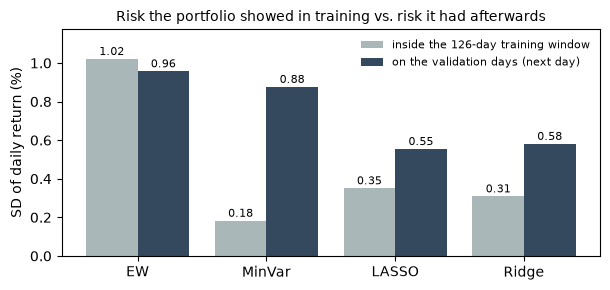

In [19]:
fig, ax = plt.subplots(figsize=(6.2, 3.0))
x = np.arange(len(BASELINE))
train = [d26[f"train sd | {n}"].mean() for n in BASELINE]
valid = [d26[n].std(ddof=1) for n in BASELINE]

ax.bar(x - 0.2, train, 0.4, label="inside the 126-day training window", color="#aab7b8")
ax.bar(x + 0.2, valid, 0.4, label="on the validation days (next day)", color="#34495e")
for xi, (a, b) in enumerate(zip(train, valid)):
    ax.text(xi - 0.2, a + 0.02, f"{a:.2f}", ha="center", fontsize=8)
    ax.text(xi + 0.2, b + 0.02, f"{b:.2f}", ha="center", fontsize=8)

ax.set_xticks(x, BASELINE)
ax.set_ylim(0, 1.15 * max(train + valid))
ax.set_ylabel("SD of daily return (%)")
ax.set_title("Risk the portfolio showed in training vs. risk it had afterwards", fontsize=10)
ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
fig.savefig(RESULTS / "fig1_overfitting.png", dpi=200)
plt.show()

**Figure 2** shows the weights of MinVar, LASSO, Ridge and Ridge with no negative weights for 2026-01-02, all built
from the same 126 days. The dashed line is the EW weight, 1/98.

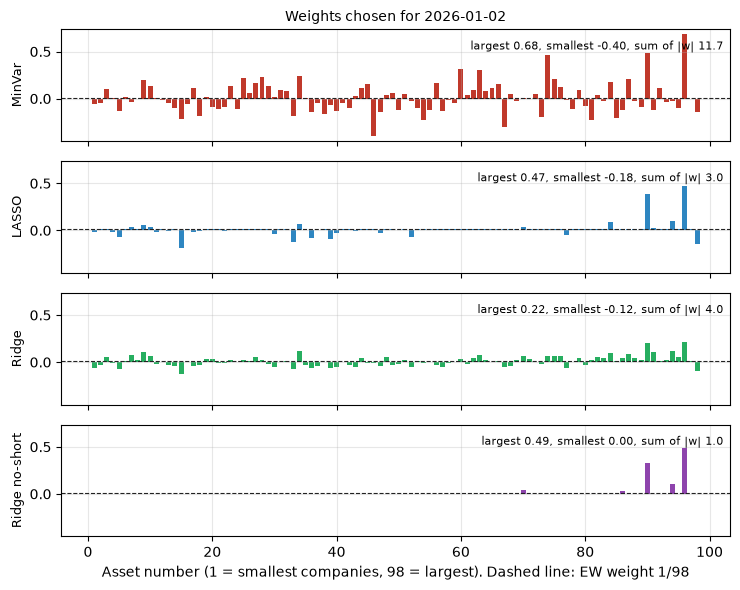

In [20]:
i = returns.index.get_loc(pd.Timestamp("2026-01-02"))
R = returns.values[i - WINDOW:i]
weights = {
    "MinVar": fit_minvar(R),
    "LASSO": fit_lasso(R)[0],
    "Ridge": fit_ridge(R)[0],
    "Ridge no-short": fit_no_short_cv(R, "ridge")[0],
}

fig, axes = plt.subplots(4, 1, figsize=(7.5, 6.0), sharex=True, sharey=True)
for ax, (n, w) in zip(axes, weights.items()):
    ax.bar(np.arange(1, 99), w, color=COLORS[n], width=0.8)
    ax.axhline(1 / 98, color="#222222", lw=0.8, ls="--")
    ax.set_ylabel(n, fontsize=9)
    ax.text(0.99, 0.9, f"largest {w.max():.2f}, smallest {w.min():.2f}, sum of |w| {np.abs(w).sum():.1f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=8)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Asset number (1 = smallest companies, 98 = largest). Dashed line: EW weight 1/98")
axes[0].set_title("Weights chosen for 2026-01-02", fontsize=10)

fig.tight_layout()
fig.savefig(RESULTS / "fig2_weights.png", dpi=200)
plt.show()

### 8. Every version and the final choice

**Table 2** shows the Sharpe ratio of every version in 2026 (the 2nd validation set), in 2025 (our extra check) and
over both periods together, which is one series of all 395 days (not the average of the two Sharpe ratios). The last
three columns repeat three of the 2026 measures of Table 1 (mean, SD and SD inside the training window) for every
version; for exploration 5.1 the training window has 1008
days.

**The rule for the final choice**, fixed before the explorations were run: among the LASSO and Ridge versions, choose
the one with the highest Sharpe ratio over both periods together. 145 days is a short period, so part of any
difference may be luck; the 250 days of 2025, which also come before the test month, give more days to judge on. EW
is the benchmark. The MinVar versions are shown for comparison but are not candidates, since the final procedure is built
with LASSO or Ridge. The choice is made among the 12 LASSO and Ridge versions in Table 2, using only the Sharpe
ratio; the measures of section 9 are for description only. Because both periods are used to choose, neither is an
untouched test, and the chosen version's Sharpe ratio over both periods may be a little higher than what it would
reach on new days.

In [21]:
explore = pd.DataFrame({
    "Sharpe 2026 (validation 2)": [sharpe(d26[n]) for n in names],
    "Sharpe 2025 (check)": [sharpe(d25[n]) for n in names],
    "Sharpe both periods": [sharpe(both[n]) for n in names],
    "mean 2026 (%)": [d26[n].mean() for n in names],
    "sd 2026 (%)": [d26[n].std(ddof=1) for n in names],
    "sd inside training window (%)": [d26[f"train sd | {n}"].mean() for n in names],
}, index=names)
explore.to_csv(RESULTS / "all_versions.csv")

candidates = [n for n in names if "LASSO" in n or "Ridge" in n]
final = explore.loc[candidates, "Sharpe both periods"].idxmax()
best_2026 = explore.loc[candidates, "Sharpe 2026 (validation 2)"].idxmax()

print("Final choice (highest Sharpe over both periods among", len(candidates), "LASSO and Ridge versions):", final)
print("For comparison, the highest Sharpe in 2026 alone:", best_2026)
explore.round(3)

Final choice (highest Sharpe over both periods among 12 LASSO and Ridge versions): Ridge groups
For comparison, the highest Sharpe in 2026 alone: Ridge no-short


,Sharpe 2026 (validation 2),Sharpe 2025 (check),Sharpe both periods,mean 2026 (%),sd 2026 (%),sd inside training window (%)
EW,0.111,0.043,0.062,0.107,0.958,1.021
MinVar,0.021,0.088,0.070,0.018,0.877,0.183
LASSO,0.061,0.052,0.053,0.034,0.555,0.351
Ridge,-0.004,0.051,0.035,-0.002,0.581,0.309
LASSO 1008d,0.056,0.051,0.052,0.037,0.649,0.656
Ridge 1008d,0.051,0.053,0.052,0.032,0.626,0.653
LASSO Sharpe-CV,0.018,0.004,0.007,0.012,0.671,0.301
Ridge Sharpe-CV,-0.012,0.053,0.034,-0.009,0.710,0.269
LASSO groups,0.029,0.120,0.093,0.019,0.675,0.607
Ridge groups,0.025,0.132,0.100,0.017,0.679,0.609


**Figure 3** shows the value of \$1 put into each baseline portfolio and into the final choice at the start of 2025
(top) and of 2026 (bottom).

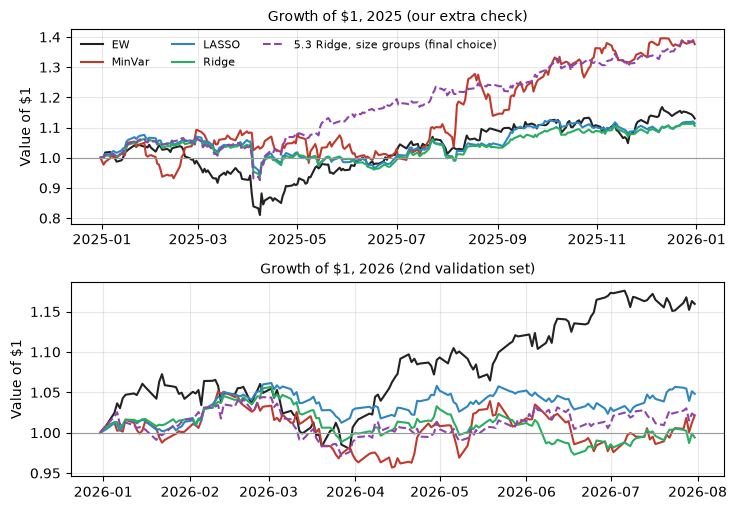

In [22]:
fig, axes = plt.subplots(2, 1, figsize=(7.5, 5.2))

for ax, (label, daily) in zip(axes, [("2025 (our extra check)", d25), ("2026 (2nd validation set)", d26)]):
    start = daily.index[0] - pd.Timedelta(days=2)

    for n in BASELINE + [final]:
        growth = (1 + daily[n] / 100).cumprod()
        growth = pd.concat([pd.Series([1.0], index=[start]), growth])
        style = "--" if n == final and n not in BASELINE else "-"
        name = f"{LABELS[n]} (final choice)" if n == final and n not in BASELINE else n
        ax.plot(growth.index, growth.values, style, lw=1.5, label=name, color=COLORS.get(n, "#8e44ad"))

    ax.axhline(1, color="#999999", lw=0.8)
    ax.set_ylabel("Value of $1")
    ax.set_title(f"Growth of $1, {label}", fontsize=10)
    ax.grid(alpha=0.3)

axes[0].legend(frameon=False, fontsize=8, ncol=3, loc="upper left")
fig.tight_layout()
fig.savefig(RESULTS / "fig3_growth.png", dpi=200)
plt.show()

**Figure 4** shows the Sharpe ratio of every version in 2026 and in 2025 separately (Table 2 has the value over both
periods together). The dashed line is EW in 2026 and the dotted line EW in 2025. Thin grey lines separate the
baseline and each exploration; in the code, `k` counts the bars from the top: 3 baseline bars (EW is shown as a
line), then 2 bars for each exploration.

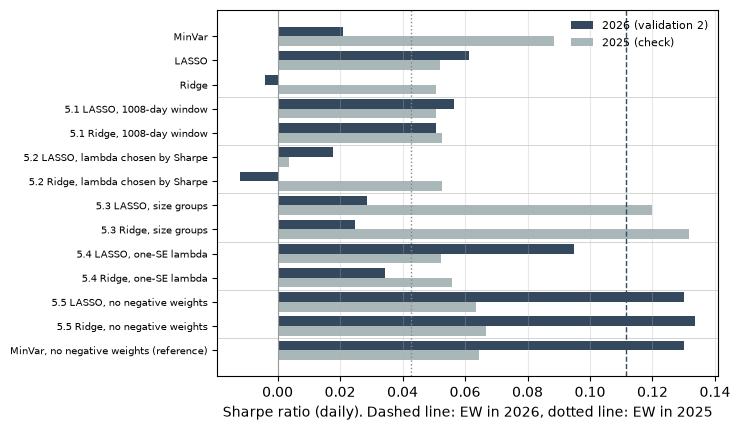

In [23]:
order = [n for n in names if n != "EW"][::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.4))
y = np.arange(len(order))

ax.barh(y + 0.2, explore.loc[order, "Sharpe 2026 (validation 2)"], 0.4, color="#34495e", label="2026 (validation 2)")
ax.barh(y - 0.2, explore.loc[order, "Sharpe 2025 (check)"], 0.4, color="#aab7b8", label="2025 (check)")
for k in [3, 5, 7, 9, 11, 13]:
    ax.axhline(len(order) - k - 0.5, color="#cccccc", lw=0.6)

ax.axvline(explore.loc["EW", "Sharpe 2026 (validation 2)"], color="#34495e", ls="--", lw=1)
ax.axvline(explore.loc["EW", "Sharpe 2025 (check)"], color="#7f8c8d", ls=":", lw=1)
ax.axvline(0, color="#999999", lw=0.8)

ax.set_yticks(y, [LABELS.get(n, n) for n in order], fontsize=7.5)
ax.set_xlabel("Sharpe ratio (daily). Dashed line: EW in 2026, dotted line: EW in 2025")
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig(RESULTS / "fig4_explorations_chart.png", dpi=200)
plt.show()

### 9. Extra measures (for description only)

Three simple measures describe how each version behaved. They are not used for the final choice, which depends only
on the Sharpe ratio (section 8). With $r_t$ the daily return in percent, the value of one dollar after day $t$ is
$V_t = \prod_{s \le t} (1 + r_s / 100)$, starting from $V_0 = 1$.

- **Maximum drawdown (%):** the largest fall of the value of one dollar below its highest earlier value,
  $100 \cdot \min_t \left( V_t / \max(V_0, \dots, V_t) - 1 \right)$. For example, −8 means that at the worst moment
  the portfolio was 8% below its best earlier value.
- **Highest value of one dollar:** $\max(V_0, V_1, \dots, V_n)$.
- **Largest weight:** the largest absolute weight on each day, averaged over the days. It shows how much the portfolio
  depends on a single asset.

In the code, `cummax()` gives the highest value so far, and the `1` in `np.maximum(..., 1)` and `max(1, ...)` stands
for the starting value $V_0$. The first table below
(**Table 3**) covers both periods together, the same 395 days as the choice; the second covers 2026 only.

In [24]:
def growth_of_1(r):
    return (1 + r / 100).cumprod()


def max_drawdown(r):
    growth = growth_of_1(r)
    peak = np.maximum(growth.cummax(), 1)
    return 100 * (growth / peak - 1).min()


def highest_value(r):
    return max(1, growth_of_1(r).max())


def describe(daily, names):
    return pd.DataFrame({
        "max drawdown (%)": [max_drawdown(daily[n]) for n in names],
        "highest value of $1": [highest_value(daily[n]) for n in names],
        "largest weight": [daily[f"largest |w| | {n}"].mean() for n in names],
    }, index=names)


extra_both = describe(both, names)
extra_2026 = describe(d26, names)

extra_both.to_csv(RESULTS / "extra_measures_both_periods.csv")
extra_2026.to_csv(RESULTS / "extra_measures_2026.csv")

extra_both.round(3)

,max drawdown (%),highest value of $1,largest weight
EW,-22.312,1.329,0.010
MinVar,-11.558,1.447,0.787
LASSO,-12.263,1.182,0.424
Ridge,-11.867,1.168,0.218
LASSO 1008d,-12.746,1.217,0.318
Ridge 1008d,-12.014,1.207,0.255
LASSO Sharpe-CV,-11.730,1.084,0.516
Ridge Sharpe-CV,-14.113,1.174,0.392
LASSO groups,-13.445,1.389,0.145
Ridge groups,-13.087,1.434,0.142


In [25]:
extra_2026.round(3)

,max drawdown (%),highest value of $1,largest weight
EW,-8.632,1.176,0.010
MinVar,-8.988,1.051,0.569
LASSO,-4.638,1.062,0.421
Ridge,-7.931,1.057,0.211
LASSO 1008d,-4.891,1.101,0.293
Ridge 1008d,-4.610,1.089,0.232
LASSO Sharpe-CV,-5.570,1.046,0.451
Ridge Sharpe-CV,-7.160,1.036,0.378
LASSO groups,-6.902,1.043,0.113
Ridge groups,-6.947,1.044,0.114


### 10. Where the money goes

**Table 4** shows the share of the money in small (size groups 1 to 3), middle (4 to 7) and large (8 to 10)
companies, averaged over the first trading day of each month, and how each of these three buckets did (the mean and SD
of its daily return, and the value of \$1 at the end). With negative weights, a share can be below 0 or above 1: a
share of 1.7 in large companies with −0.7 in middle ones adds up to 1. The printed line counts how many of LASSO's 97 coefficients are exactly 0 on
those days in 2026.

In [26]:
buckets = {"small (groups 1-3)": [1, 2, 3], "middle (groups 4-7)": [4, 5, 6, 7], "large (groups 8-10)": [8, 9, 10]}
in_bucket = {b: np.isin(groups, gs) for b, gs in buckets.items()}
shown = BASELINE + ["LASSO groups", "Ridge groups", "LASSO no-short", "Ridge no-short"]

rows = {}
zero_betas = []

for year in ["2026", "2025"]:
    first, last = PERIODS[year]
    days = returns.loc[first:last]
    firsts = days.groupby(days.index.month).head(1).index
    shares = {n: np.zeros(3) for n in shown}

    for day in firsts:
        i = returns.index.get_loc(day)
        R = returns.values[i - WINDOW:i]
        G = group_returns(R, groups)

        w_lasso, lasso = fit_lasso(R)
        if year == "2026":
            zero_betas.append(int(np.sum(lasso.coef_ == 0)))

        w_day = {
            "EW": np.ones(98) / 98,
            "MinVar": fit_minvar(R),
            "LASSO": w_lasso,
            "Ridge": fit_ridge(R)[0],
            "LASSO groups": spread_to_assets(fit_lasso(G)[0], groups),
            "Ridge groups": spread_to_assets(fit_ridge(G)[0], groups),
            "LASSO no-short": fit_no_short_cv(R, "lasso")[0],
            "Ridge no-short": fit_no_short_cv(R, "ridge")[0],
        }
        for n, w in w_day.items():
            shares[n] += np.array([w[m].sum() for m in in_bucket.values()]) / len(firsts)

    for n, share in shares.items():
        rows[f"{year}: share of money, {n}"] = share

    bucket_returns = pd.DataFrame({b: days.loc[:, m].mean(axis=1) for b, m in in_bucket.items()})
    rows[f"{year}: mean daily return of the bucket (%)"] = bucket_returns.mean().values
    rows[f"{year}: SD of the bucket's daily return (%)"] = bucket_returns.std(ddof=1).values
    rows[f"{year}: value of $1 at the end"] = (1 + bucket_returns / 100).prod().values

size_table = pd.DataFrame(rows, index=list(buckets)).T
size_table.to_csv(RESULTS / "size_buckets.csv")
print("LASSO coefficients exactly 0 on the first trading day of each month in 2026:", zero_betas,
      "of 97, average", round(np.mean(zero_betas), 1))
size_table.round(3)

LASSO coefficients exactly 0 on the first trading day of each month in 2026: [64, 35, 65, 54, 63, 60, 65] of 97, average 58.0


,small (groups 1-3),middle (groups 4-7),large (groups 8-10)
"2026: share of money, EW",0.306,0.408,0.286
"2026: share of money, MinVar",0.274,-0.364,1.090
"2026: share of money, LASSO",0.083,-0.072,0.988
"2026: share of money, Ridge",0.138,-0.201,1.063
"2026: share of money, LASSO groups",0.008,-0.690,1.682
"2026: share of money, Ridge groups",-0.041,-0.612,1.653
"2026: share of money, LASSO no-short",0.002,0.048,0.950
"2026: share of money, Ridge no-short",0.003,0.053,0.945
2026: mean daily return of the bucket (%),0.126,0.115,0.073
2026: SD of the bucket's daily return (%),1.253,0.985,0.762


## Conclusion

These points describe what we saw in these two periods. With 145 and 250 days, part of each difference may be luck.

- **MinVar seems to overfit.** Inside its 126-day training windows its daily returns had an SD of 0.18% on average,
  but on the 2026 validation days the SD was 0.88% (Table 1, Figure 1). Its 97 coefficients, estimated from 126 days,
  seem to fit much of the noise of each window.
- **LASSO and Ridge seem to reduce this.** Their SD was 0.35% and 0.31% inside the training windows and 0.55% and
  0.58% on the 2026 validation days, a much smaller gap than MinVar's, and below EW's 0.96%. In 2026 their average
  return was also lower than EW's, so their Sharpe ratios (0.061 and −0.004) stayed below EW's 0.111. In 2025 the order
  was the other way round: MinVar (0.088), LASSO (0.052) and Ridge (0.051) were all above EW (0.043).
- **No negative weights (exploration 5.5)** gave the highest Sharpe ratios in 2026: 0.130 for LASSO and 0.134 for
  Ridge, above EW. In 2025 they reached 0.063 and 0.067, above EW but below the size-group versions. The version with
  λ = 0 scored almost the same (0.130 in 2026, 0.065 in 2025), which suggests that most of the effect comes from the
  rule itself rather than from the penalty. On 2026-01-02 each of the two versions with no negative weights held
  only 5 of the 98 assets with a weight above 0.001.
- **The final choice.** By the rule fixed in advance (section 8), the final procedure is **Ridge with one weight per
  size group**: a Sharpe ratio of 0.100 over both periods, against 0.062 for EW. Its lead comes from 2025 (0.132); in
  2026 it reached only 0.025, below EW. On 2026 alone, the same rule would have picked Ridge with no negative weights
  (0.134). Over both periods, the next LASSO and Ridge versions were LASSO with size groups (0.093) and
  the two versions with no negative weights (0.081 for Ridge and 0.078 for LASSO).
- **The extra measures (section 9)** add a few points. Over both periods, every LASSO and Ridge version had a smaller
  worst fall than EW (maximum drawdowns between −11.7% and −14.9%, against −22.3% for EW). Among the 12 LASSO and
  Ridge versions, the chosen version reached the highest value of one dollar (1.43, against 1.33 for EW) and
  kept its largest weight small (0.14 on average), while the versions with no negative weights put about 0.4 of the
  money in a single asset.

**Limitations.** For a daily Sharpe ratio over 145 days, a rough standard error is $1/\sqrt{145} \approx 0.08$; over
the 395 days of both periods it is about $1/\sqrt{395} \approx 0.05$. The chosen version's lead over EW (0.100
against 0.062) is smaller than this, and its lead over LASSO with size groups (0.093) is smaller still, so many of the
differences above may partly be luck. The two periods also disagree: the size-group versions, the best in 2025, were in
the lower half of the LASSO and Ridge versions in 2026. Only the versions with no negative weights were above EW in
both periods.